# Import Libraries

In [ ]:
#Data Loading
import pandas  as pd
##Preprocessing
import numpy   as np
from sklearn.preprocessing import MinMaxScaler
#Balancing
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

#MLP
from sklearn.neural_network import MLPClassifier
#Naive Bayes
from sklearn.naive_bayes import GaussianNB
#KNN
from sklearn.neighbors import KNeighborsClassifier
#Nearest Centroid
from sklearn.neighbors import NearestCentroid
#SFS
from sklearn.feature_selection import SequentialFeatureSelector
#PCA
from sklearn.decomposition import PCA
#plot
import matplotlib.pyplot as plt
#ROC
from sklearn.metrics import roc_curve,roc_auc_score

#metrics
from sklearn import metrics
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
from sklearn.model_selection import cross_val_score,StratifiedKFold
from sklearn.model_selection import GridSearchCV

# Import Data

In [2]:
df = pd.read_csv('data.csv')
df.shape

(568, 32)

In [5]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
563,926125,M,20.92,25.09,143.0,1347.0,0.10990,0.2236,0.31740,0.14740,...,24.29,29.41,179.1,1819.0,0.1407,0.4186,0.6599,0.2542,0.2929,0.09873
564,926424,M,21.56,22.39,142.0,1479.0,0.11100,0.1159,0.24390,0.13890,...,25.45,26.40,166.1,2027.0,0.1410,0.2113,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.2,1261.0,0.09780,0.1034,0.14400,0.09791,...,23.69,38.25,155.0,1731.0,0.1166,0.1922,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.3,858.1,0.08455,0.1023,0.09251,0.05302,...,18.98,34.12,126.7,1124.0,0.1139,0.3094,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.1,1265.0,0.11780,0.2770,0.35140,0.15200,...,25.74,39.42,184.6,1821.0,0.1650,0.8681,0.9387,0.2650,0.4087,0.12400


In [7]:
df.dtypes

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568 entries, 0 to 567
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       568 non-null    int64  
 1   diagnosis                568 non-null    object 
 2   radius_mean              568 non-null    float64
 3   texture_mean             568 non-null    float64
 4   perimeter_mean           568 non-null    float64
 5   area_mean                568 non-null    float64
 6   smoothness_mean          568 non-null    float64
 7   compactness_mean         568 non-null    float64
 8   concavity_mean           568 non-null    float64
 9   concave points_mean      568 non-null    float64
 10  symmetry_mean            568 non-null    float64
 11  fractal_dimension_mean   568 non-null    float64
 12  radius_se                568 non-null    float64
 13  texture_se               568 non-null    float64
 14  perimeter_se             5

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,568.0,3.042514e+07,1.251243e+08,8670.000000,869222.500000,906157.000000,8.825022e+06,9.113205e+08
radius_mean,568.0,1.413850e+01,3.516986e+00,6.981000,11.707500,13.375000,1.579750e+01,2.811000e+01
texture_mean,568.0,1.928040e+01,4.299166e+00,9.710000,16.170000,18.835000,2.178500e+01,3.928000e+01
perimeter_mean,568.0,9.204658e+01,2.424982e+01,43.790000,75.200000,86.290000,1.041500e+02,1.885000e+02
area_mean,568.0,6.557234e+02,3.516606e+02,143.500000,420.300000,551.400000,7.841500e+02,2.501000e+03
smoothness_mean,568.0,9.643727e-02,1.395600e-02,0.062510,0.086400,0.095895,1.053250e-01,1.634000e-01
compactness_mean,568.0,1.044479e-01,5.279766e-02,0.019380,0.065175,0.093125,1.304250e-01,3.454000e-01
concavity_mean,568.0,8.895565e-02,7.970273e-02,0.000000,0.029575,0.061545,1.310000e-01,4.268000e-01
concave points_mean,568.0,4.900527e-02,3.878258e-02,0.000000,0.020348,0.033600,7.401000e-02,2.012000e-01
symmetry_mean,568.0,1.812014e-01,2.742220e-02,0.106000,0.161975,0.179250,1.957000e-01,3.040000e-01


In [10]:
df.diagnosis.unique()
df['diagnosis'].value_counts()

diagnosis
B    356
M    212
Name: count, dtype: int64

In [11]:
df = df.drop(columns=['id'],axis=1)

df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Preprocessing

In [12]:
df['diagnosis'] = df['diagnosis'].map({'M':1, 'B':0})
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
563,1,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,0.2149,...,24.29,29.41,179.10,1819.0,0.1407,0.4186,0.6599,0.2542,0.2929,0.09873
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.45,26.40,166.10,2027.0,0.1410,0.2113,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.69,38.25,155.00,1731.0,0.1166,0.1922,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.98,34.12,126.70,1124.0,0.1139,0.3094,0.3403,0.1418,0.2218,0.07820


In [13]:
num_duplicates = df.duplicated().sum()
df_no_duplicates = df.drop_duplicates()
print(f"تعداد ردیف‌های تکراری: {num_duplicates}")

تعداد ردیف‌های تکراری: 0


In [15]:
for i in df.columns:
    print (i,len(df[df[i]=='?']))

diagnosis 0
radius_mean 0
texture_mean 0
perimeter_mean 0
area_mean 0
smoothness_mean 0
compactness_mean 0
concavity_mean 0
concave points_mean 0
symmetry_mean 0
fractal_dimension_mean 0
radius_se 0
texture_se 0
perimeter_se 0
area_se 0
smoothness_se 0
compactness_se 0
concavity_se 0
concave points_se 0
symmetry_se 0
fractal_dimension_se 0
radius_worst 0
texture_worst 0
perimeter_worst 0
area_worst 0
smoothness_worst 0
compactness_worst 0
concavity_worst 0
concave points_worst 0
symmetry_worst 0
fractal_dimension_worst 0


## Outlier Detection

### Quantline Method

In [16]:
df_ADD2 = df.copy()
Q1 = df_ADD2.quantile(0.25)
Q3 = df_ADD2.quantile(0.75)
IQR = Q3 - Q1
print(((df_ADD2 < (Q1 - 1.5 *IQR)) | (df_ADD2 > (Q3 + 1.5*IQR))).sum())

diagnosis                   0
radius_mean                14
texture_mean                7
perimeter_mean             13
area_mean                  25
smoothness_mean             5
compactness_mean           17
concavity_mean             18
concave points_mean        10
symmetry_mean              15
fractal_dimension_mean     15
radius_se                  38
texture_se                 20
perimeter_se               38
area_se                    64
smoothness_se              29
compactness_se             28
concavity_se               22
concave points_se          19
symmetry_se                27
fractal_dimension_se       28
radius_worst               17
texture_worst               5
perimeter_worst            15
area_worst                 34
smoothness_worst            7
compactness_worst          16
concavity_worst            12
concave points_worst        0
symmetry_worst             23
fractal_dimension_worst    24
dtype: int64


In [17]:
df_AOD_Quantline = df_ADD2[~((df_ADD2 < (Q1 - 1.5 * IQR)) | (df_ADD2 > (Q3 + 1.5 * IQR))).any(axis=1)]
df_AOD_Quantline

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
6,1,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368
7,1,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510
10,1,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,...,19.19,33.88,123.80,1150.0,0.1181,0.1551,0.1459,0.09975,0.2948,0.08452
11,1,15.78,17.89,103.60,781.0,0.09710,0.12920,0.09954,0.06606,0.1842,...,20.42,27.28,136.50,1299.0,0.1396,0.5609,0.3965,0.18100,0.3792,0.10480
13,1,15.85,23.95,103.70,782.7,0.08401,0.10020,0.09938,0.05364,0.1847,...,16.84,27.66,112.00,876.5,0.1131,0.1924,0.2322,0.11190,0.2809,0.06287
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
554,0,12.88,28.92,82.50,514.3,0.08123,0.05824,0.06195,0.02343,0.1566,...,13.89,35.74,88.84,595.7,0.1227,0.1620,0.2439,0.06493,0.2372,0.07242
555,0,10.29,27.61,65.67,321.4,0.09030,0.07658,0.05999,0.02738,0.1593,...,10.84,34.91,69.57,357.6,0.1384,0.1710,0.2000,0.09127,0.2226,0.08283
558,0,14.59,22.68,96.39,657.1,0.08473,0.13300,0.10290,0.03736,0.1454,...,15.48,27.27,105.90,733.5,0.1026,0.3171,0.3662,0.11050,0.2258,0.08004
560,0,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,0.1537,...,15.30,33.17,100.20,706.7,0.1241,0.2264,0.1326,0.10480,0.2250,0.08321


In [18]:
df_AOD_Quantline.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

## Standardization

### Min Max

In [19]:
scaler = MinMaxScaler()
Min_Max_Scaled = scaler.fit_transform(df_AOD_Quantline)
df_Min_Max = pd.DataFrame(Min_Max_Scaled, columns=list(df_AOD_Quantline.columns))
df_Min_Max

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1.0,0.828055,0.510945,0.806404,0.762006,0.508308,0.490209,0.442829,0.587768,0.485294,...,0.898978,0.548387,0.886197,0.842305,0.590802,0.387182,0.489711,0.759733,0.545842,0.436055
1,1.0,0.494452,0.553234,0.493671,0.369231,0.892388,0.793786,0.368016,0.475377,0.796440,...,0.549008,0.565217,0.518924,0.421982,0.789770,0.578969,0.346577,0.611876,0.602559,0.917292
2,1.0,0.664193,0.673134,0.626635,0.556141,0.309384,0.258779,0.129627,0.263940,0.279412,...,0.677090,0.766480,0.632727,0.571971,0.345847,0.209440,0.188818,0.392253,0.496802,0.448920
3,1.0,0.646557,0.406965,0.636209,0.541861,0.547397,0.600700,0.391120,0.524702,0.522446,...,0.751052,0.535063,0.742219,0.660304,0.547630,0.913123,0.513136,0.711758,0.856716,0.759534
4,1.0,0.651701,0.708458,0.637273,0.543306,0.340244,0.442074,0.390491,0.426052,0.526316,...,0.535779,0.548387,0.530994,0.409829,0.298921,0.274121,0.300505,0.440031,0.437527,0.117323
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
393,0.0,0.433463,0.955721,0.411765,0.315172,0.296249,0.212559,0.243418,0.186100,0.308824,...,0.358388,0.831697,0.331322,0.243360,0.389019,0.221405,0.315646,0.255328,0.251173,0.263593
394,0.0,0.243148,0.890547,0.232741,0.151211,0.439785,0.312876,0.235717,0.217474,0.329721,...,0.174985,0.802595,0.165187,0.102205,0.536368,0.237012,0.258833,0.358907,0.188913,0.423036
395,0.0,0.559115,0.645274,0.559515,0.436549,0.351638,0.621486,0.404322,0.296743,0.222136,...,0.453999,0.534712,0.478403,0.325053,0.200375,0.490359,0.473923,0.434526,0.202559,0.380303
396,0.0,0.519436,0.867662,0.506223,0.388355,0.582054,0.509900,0.175324,0.341859,0.286378,...,0.443175,0.741585,0.429261,0.309165,0.402159,0.333079,0.171606,0.412112,0.199147,0.428856


# Balancing

In [20]:
Y = df_Min_Max['diagnosis']
X = df_Min_Max.drop('diagnosis',axis= 1)

In [21]:
print("Class 1 --->", sum(Y==1))
print("Class 0 --->", sum(Y==0))
print("Count of Class 1 / Count of Class 0--->", sum(Y==1)/sum(Y==0))

Class 1 ---> 98
Class 0 ---> 300
Count of Class 1 / Count of Class 0---> 0.32666666666666666


In [22]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=1)

In [23]:
X_train.shape,Y_train.shape

((318, 30), (318,))

In [24]:
print("Class 1 --->", sum(Y==1))
print("Class 0 --->", sum(Y==0))
print("Count of Class 1 / Count of Class 0--->", sum(Y==1)/sum(Y==0))

Class 1 ---> 98
Class 0 ---> 300
Count of Class 1 / Count of Class 0---> 0.32666666666666666


## Stratify

In [25]:
X_train, X_test, Y_train, Y_test= train_test_split(X, Y, test_size=0.2, random_state=1, stratify=Y)

In [26]:
X_train.shape, Y_train.shape

((318, 30), (318,))

In [27]:
X_test.shape, Y_test.shape

((80, 30), (80,))

In [28]:
print("Class 1 --->", sum(Y==1))
print("Class 0 --->", sum(Y==0))
print("Count of Class 1 / Count of Class 0--->", sum(Y==1)/sum(Y==0))

Class 1 ---> 98
Class 0 ---> 300
Count of Class 1 / Count of Class 0---> 0.32666666666666666


# OverSampling

In [29]:
sm = SMOTE(random_state=2)

print("\nclass 1 before Over Sampling --> ", sum(Y_train==1))
print("\nclass 0 before Over Sampling --> ", sum(Y_train==0))

X_train_OS,Y_train_OS= sm.fit_resample(X_train, Y_train.to_numpy())
print("\nThe shape of The X after Over Sampling --> ", X_train_OS.shape)
print("\nThe shape of The Y after Over Sampling --> ", Y_train_OS.shape)


print("\nclass 1 after Over Sampling --> ", sum(Y_train_OS==1))
print("\nclass 0 after Over Sampling --> ", sum(Y_train_OS==0))
print("\n")


class 1 before Over Sampling -->  78

class 0 before Over Sampling -->  240

The shape of The X after Over Sampling -->  (480, 30)

The shape of The Y after Over Sampling -->  (480,)

class 1 after Over Sampling -->  240

class 0 after Over Sampling -->  240




In [30]:
X_train_OS.shape,Y_train_OS.shape

((480, 30), (480,))

In [31]:
X_test.shape,Y_test.shape

((80, 30), (80,))

# MLP

## Parameter Tuning

In [32]:
parameters = {
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'hidden_layer_sizes': [(i,) for i in range(10, 15)],
    'max_iter':[100,500]
}

CV = StratifiedKFold(n_splits=5)
clf = MLPClassifier(early_stopping=True, random_state=42)

search = GridSearchCV(estimator=clf, cv=CV, param_grid=parameters, verbose=1)
search.fit(X_train_OS, Y_train_OS)

print("Best parameters:", search.best_params_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters: {'activation': 'relu', 'hidden_layer_sizes': (13,), 'max_iter': 100, 'solver': 'adam'}


In [33]:
MLP = MLPClassifier(
    activation=search.best_params_['activation'],
    solver=search.best_params_['solver'],
    hidden_layer_sizes=search.best_params_['hidden_layer_sizes'],
    max_iter=search.best_params_['max_iter'],
    random_state=42
)
MLP.fit(X_train_OS,Y_train_OS)


CV = StratifiedKFold(n_splits=5)
CV_Scores_MLP= cross_val_score(MLP,X_train_OS,Y_train_OS,cv=CV)
CV_score_df_MLP = pd.DataFrame(CV_Scores_MLP,columns=['Accuracy'])
display(CV_score_df_MLP)
print('The Avarage of CV Scores: ',CV_score_df_MLP.Accuracy.mean())

c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and 

,Accuracy
0,0.895833
1,0.885417
2,0.927083
3,0.895833
4,0.937500


The Avarage of CV Scores:  0.9083333333333334


In [34]:
y_predict_MLP = MLP.predict(X_test)

print('\nClassification_report:\n',classification_report(Y_test,y_predict_MLP))


conf_matrix_MLP= metrics.confusion_matrix(y_predict_MLP,Y_test)
conf_matrix_df_MLP = pd.DataFrame(conf_matrix_MLP, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_matrix_df_MLP


Classification_report:
               precision    recall  f1-score   support

         0.0       0.96      0.92      0.94        60
         1.0       0.78      0.90      0.84        20

    accuracy                           0.91        80
   macro avg       0.87      0.91      0.89        80
weighted avg       0.92      0.91      0.91        80



,Predicted 0,Predicted 1
Actual 0,55,2
Actual 1,5,18


# Naive Bayes

In [35]:
gnb = GaussianNB()
gnb.fit(X_train_OS,Y_train_OS)

CV_Scores_NB = cross_val_score(gnb,X_train_OS,Y_train_OS,cv=CV)
CV_score_df_NB = pd.DataFrame(CV_Scores_NB,columns=['Accuracy'])
display(CV_score_df_NB)
print('The Avarage of CV Scores: ',CV_score_df_NB.Accuracy.mean())


,Accuracy
0,0.916667
1,0.937500
2,0.937500
3,0.916667
4,0.947917


The Avarage of CV Scores:  0.93125


In [36]:
y_predict_gnb = gnb.predict(X_test)

print('\nClassification_report:\n',classification_report(Y_test,y_predict_gnb))


conf_matrix_NB = metrics.confusion_matrix(y_predict_gnb,Y_test)
conf_matrix_df_NB = pd.DataFrame(conf_matrix_NB, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_matrix_df_NB


Classification_report:
               precision    recall  f1-score   support

         0.0       0.97      0.97      0.97        60
         1.0       0.90      0.90      0.90        20

    accuracy                           0.95        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.95      0.95      0.95        80



,Predicted 0,Predicted 1
Actual 0,58,2
Actual 1,2,18


# Nearest Neighbor

In [37]:
nn = KNeighborsClassifier(n_neighbors=1)
nn.fit(X_train_OS,Y_train_OS)

CV_scores_nn = cross_val_score(nn, X_train_OS, Y_train_OS, cv=5, scoring='accuracy')
CV_score_df_nn = pd.DataFrame(CV_scores_nn, columns=['Accuracy'])
display(CV_score_df_nn)

print('The Average of CV Scores:', CV_score_df_nn.Accuracy.mean())

,Accuracy
0,0.989583
1,0.979167
2,0.968750
3,0.979167
4,0.947917


The Average of CV Scores: 0.9729166666666667


In [38]:
y_predict_nn = nn.predict(X_test)

print('\nClassification_report:\n',classification_report(Y_test,y_predict_nn))


conf_matrix_NN = metrics.confusion_matrix(y_predict_nn,Y_test)
conf_matrix_df_NN = pd.DataFrame(conf_matrix_NN, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_matrix_df_NN


Classification_report:
               precision    recall  f1-score   support

         0.0       0.97      0.95      0.96        60
         1.0       0.86      0.90      0.88        20

    accuracy                           0.94        80
   macro avg       0.91      0.93      0.92        80
weighted avg       0.94      0.94      0.94        80



,Predicted 0,Predicted 1
Actual 0,57,2
Actual 1,3,18


# KNN

## Parameter Tuning

In [ ]:
parameters_KNN = {
    'weights': ['uniform', 'distance'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'n_neighbors': list(range(2, 21)) 
}

CV = StratifiedKFold(n_splits=5)
clf = KNeighborsClassifier()

search = GridSearchCV(estimator=clf, cv=CV, param_grid=parameters_KNN, verbose=1)
search.fit(X_train_OS, Y_train_OS)

print("Best parameters:", search.best_params_)


Fitting 5 folds for each of 152 candidates, totalling 760 fits
Best parameters: {'algorithm': 'auto', 'n_neighbors': 2, 'weights': 'uniform'}


Best k: {'algorithm': 'auto', 'n_neighbors': 2, 'weights': 'uniform'}
k = 2, mean accuracy = 0.9771
k = 3, mean accuracy = 0.9729
k = 4, mean accuracy = 0.9688
k = 5, mean accuracy = 0.9729
k = 6, mean accuracy = 0.9677
k = 7, mean accuracy = 0.9635
k = 8, mean accuracy = 0.9688
k = 9, mean accuracy = 0.9688
k = 10, mean accuracy = 0.9688
k = 11, mean accuracy = 0.9688
k = 12, mean accuracy = 0.9708
k = 13, mean accuracy = 0.9677
k = 14, mean accuracy = 0.9656
k = 15, mean accuracy = 0.9656
k = 16, mean accuracy = 0.9677
k = 17, mean accuracy = 0.9677
k = 18, mean accuracy = 0.9688
k = 19, mean accuracy = 0.9677
k = 20, mean accuracy = 0.9667


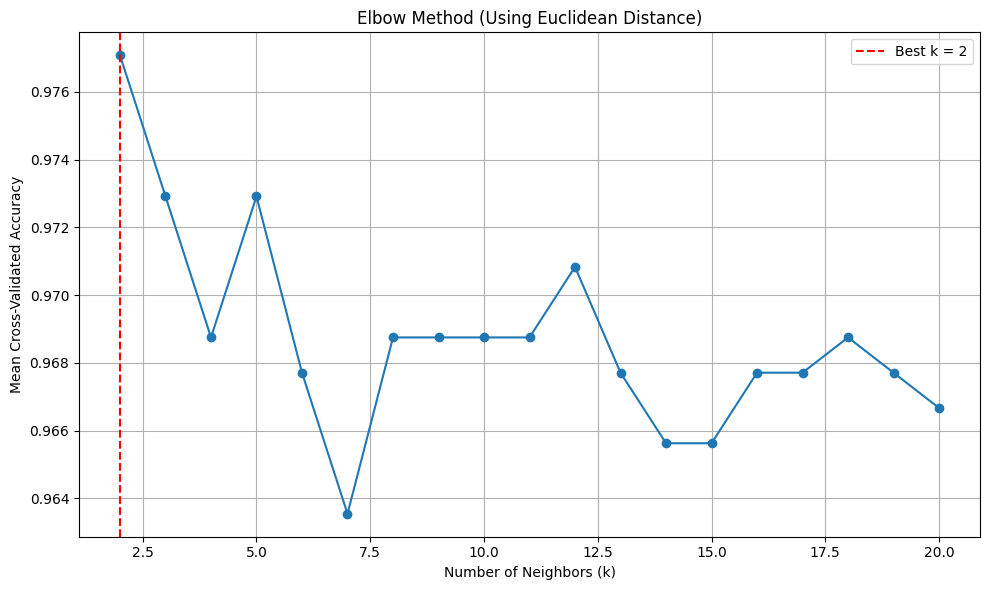

In [ ]:


# parameters_KNN = {
#     'weights': ['uniform', 'distance'],
#     'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
#     'n_neighbors': list(range(2, 21)) 
# }

# grid = GridSearchCV(KNeighborsClassifier(), parameters_KNN, cv=5, scoring='accuracy', return_train_score=True)
# grid.fit(X_train_OS, Y_train_OS)

# # نمایش بهترین مقدار
# print("Best k:", grid.best_params_)

# # استخراج میانگین دقت برای هر k
# results = grid.cv_results_
# k_score_map = {}  # برای محاسبه میانگین هر k
# for mean_score, params in zip(results["mean_test_score"], results["params"]):
#     k = params['n_neighbors']
#     if k not in k_score_map:
#         k_score_map[k] = []
#     k_score_map[k].append(mean_score)

# # ساخت لیست برای رسم نمودار
# k_values = sorted(k_score_map.keys())
# avg_scores = [sum(k_score_map[k])/len(k_score_map[k]) for k in k_values]
# optimal_k = k_values[avg_scores.index(max(avg_scores))]

# # چاپ نتایج
# for k, score in zip(k_values, avg_scores):
#     print(f"k = {k}, mean accuracy = {score:.4f}")

# # رسم نمودار Elbow
# plt.figure(figsize=(10, 6))
# plt.plot(k_values, avg_scores, marker='o')
# plt.xlabel('Number of Neighbors (k)')
# plt.ylabel('Mean Cross-Validated Accuracy')
# plt.title('Elbow Method (Using Euclidean Distance)')
# plt.axvline(optimal_k, color='red', linestyle='--', label=f'Best k = {optimal_k}')
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()


Best k based on Euclidean distance: 2
Best CV Accuracy: 0.9812


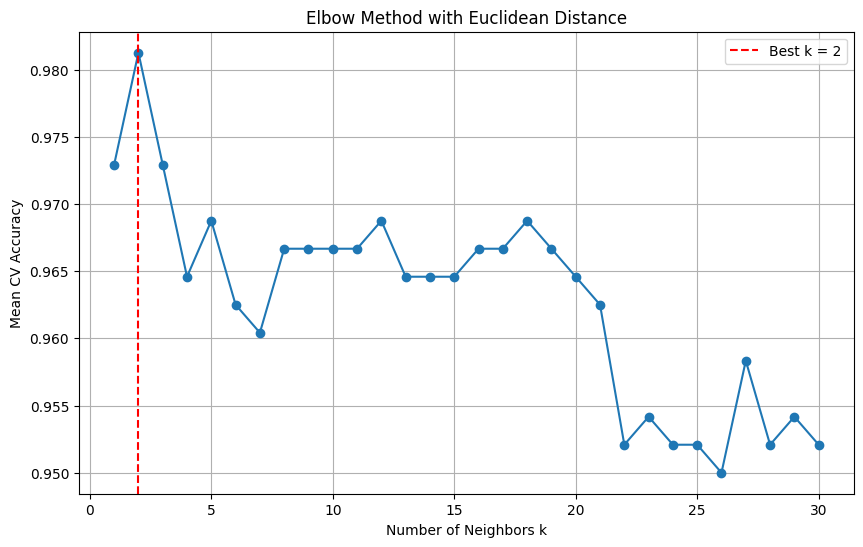

In [ ]:
# k_values = range(1, 31)
# cv_scores = []

# for k in k_values:
#     knn = KNeighborsClassifier(
#         n_neighbors=k,
#         weights='uniform',      
#         algorithm='brute',      
#         metric='minkowski',    
#         p=2                     
#     )
#     scores = cross_val_score(knn, X_train_OS, Y_train_OS, cv=5, scoring='accuracy')
#     cv_scores.append(scores.mean())

# # پیدا کردن بهترین مقدار k
# optimal_k = k_values[np.argmax(cv_scores)]
# print(f"Best k based on Euclidean distance: {optimal_k}")
# print(f"Best CV Accuracy: {max(cv_scores):.4f}")

# # رسم نمودار Elbow
# plt.figure(figsize=(10, 6))
# plt.plot(k_values, cv_scores, marker='o')
# plt.xlabel('Number of Neighbors k')
# plt.ylabel('Mean CV Accuracy')
# plt.title('Elbow Method with Euclidean Distance')
# plt.axvline(optimal_k, color='red', linestyle='--', label=f'Best k = {optimal_k}')
# plt.grid(True)
# plt.legend()
# plt.show()

In [58]:
KNN = KNeighborsClassifier (
    weights = search.best_params_['weights'],
    algorithm= search.best_params_['algorithm'],
    n_neighbors= search.best_params_['n_neighbors']    
)

KNN.fit(X_train_OS,Y_train_OS)


CV = StratifiedKFold(n_splits=5)
CV_Scores_KNN= cross_val_score(KNN,X_train_OS,Y_train_OS,cv=CV)
CV_score_df_KNN = pd.DataFrame(CV_Scores_KNN,columns=['Accuracy'])
display(CV_score_df_KNN)
print('The Avarage of CV Scores: ',CV_score_df_KNN.Accuracy.mean())

,Accuracy
0,0.989583
1,0.989583
2,0.979167
3,0.989583
4,0.958333


The Avarage of CV Scores:  0.98125


In [59]:
y_predict_KNN = KNN.predict(X_test)

print('\nClassification_report:\n',classification_report(Y_test,y_predict_KNN))


conf_matrix_KNN = metrics.confusion_matrix(y_predict_KNN,Y_test)
conf_matrix_df_KNN = pd.DataFrame(conf_matrix_KNN, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_matrix_df_KNN


Classification_report:
               precision    recall  f1-score   support

         0.0       0.97      0.97      0.97        60
         1.0       0.90      0.90      0.90        20

    accuracy                           0.95        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.95      0.95      0.95        80



,Predicted 0,Predicted 1
Actual 0,58,2
Actual 1,2,18


# Nearest Centroid

In [40]:
NC = NearestCentroid()
NC.fit(X_train_OS,Y_train_OS)

CV_Scores_NC = cross_val_score(NC,X_train_OS,Y_train_OS,cv=CV)
CV_score_df_NC = pd.DataFrame(CV_Scores_NC,columns=['Accuracy'])
display(CV_score_df_NC)
print('The Avarage of CV Scores: ',CV_score_df_NC.Accuracy.mean())

,Accuracy
0,0.885417
1,0.927083
2,0.937500
3,0.906250
4,0.958333


The Avarage of CV Scores:  0.9229166666666666


In [41]:
y_predict_NC = NC.predict(X_test)

print('\nClassification_report:\n',classification_report(Y_test,y_predict_NC))


conf_matrix_NC = metrics.confusion_matrix(y_predict_NC,Y_test)
conf_matrix_df_NC = pd.DataFrame(conf_matrix_NC, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_matrix_df_NC


Classification_report:
               precision    recall  f1-score   support

         0.0       0.97      0.97      0.97        60
         1.0       0.90      0.90      0.90        20

    accuracy                           0.95        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.95      0.95      0.95        80



,Predicted 0,Predicted 1
Actual 0,58,2
Actual 1,2,18


In [ ]:
mu_0 = NC.centroids_[0]  # مرکز کلاس 0
mu_1 = NC.centroids_[1]  # مرکز کلاس 1

# محاسبه پارامترهای معادله
W = 2 * (mu_1 - mu_0)
b = np.dot(mu_0, mu_0) - np.dot(mu_1, mu_1)


try:
    feature_names = X_train_OS.columns 
except:
    feature_names = [f"x{i}" for i in range(X_train_OS.shape[1])] 

equation = " + ".join([f"{W[i]:.3f}*{feature_names[i]}" for i in range(len(W))])
print("\n Decision Boundary Equation:")
print(f"{equation} + ({b:.3f}) = 0")


 Decision Boundary Equation:
0.551*radius_mean + 0.320*texture_mean + 0.557*perimeter_mean + 0.585*area_mean + 0.289*smoothness_mean + 0.490*compactness_mean + 0.662*concavity_mean + 0.728*concave points_mean + 0.222*symmetry_mean + -0.005*fractal_dimension_mean + 0.503*radius_se + -0.010*texture_se + 0.504*perimeter_se + 0.621*area_se + -0.075*smoothness_se + 0.195*compactness_se + 0.277*concavity_se + 0.303*concave points_se + -0.193*symmetry_se + 0.065*fractal_dimension_se + 0.667*radius_worst + 0.383*texture_worst + 0.665*perimeter_worst + 0.680*area_worst + 0.370*smoothness_worst + 0.486*compactness_worst + 0.599*concavity_worst + 0.676*concave points_worst + 0.336*symmetry_worst + 0.314*fractal_dimension_worst + (-5.135) = 0


# Forward Sequential Feature Selection

## MLP

In [43]:
fsfs_MLP = SequentialFeatureSelector(
    MLP,
    direction='forward',
    n_jobs=-1
)


fsfs_MLP.fit(X_train_OS, np.ravel(Y_train_OS))


X_train_fsfs_MLP = pd.DataFrame(
    fsfs_MLP.transform(X_train_OS),
    columns=fsfs_MLP.get_feature_names_out()
)
X_test_fsfs_MLP = pd.DataFrame(
    fsfs_MLP.transform(X_test),
    columns=fsfs_MLP.get_feature_names_out()
)
X_test_fsfs_MLP

,radius_mean,texture_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,perimeter_se,compactness_se,symmetry_se,texture_worst,area_worst,smoothness_worst,concavity_worst,symmetry_worst
0,0.815563,0.603483,0.748406,0.177243,0.366699,0.433399,0.458936,0.797264,0.944846,0.465119,0.444600,0.618212,0.065415,0.328070,0.249893
1,0.351165,0.591542,0.241734,0.377591,0.165627,0.065108,0.088562,0.421171,0.139860,0.569429,0.480365,0.196407,0.255748,0.071477,0.277186
2,0.337203,0.464179,0.226264,0.363190,0.316377,0.215521,0.113423,0.324961,0.339457,0.358457,0.524544,0.198779,0.409667,0.331306,0.533902
3,0.462121,0.251244,0.346961,0.174711,0.170496,0.128134,0.210326,0.435972,0.151450,0.045135,0.362202,0.382618,0.181605,0.174712,0.104051
4,0.979425,0.863184,0.972801,0.593290,0.489115,0.596857,0.741303,0.410406,0.252068,0.128662,0.951613,0.983401,0.665885,0.490229,0.583369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.926519,0.760697,0.890353,0.643931,0.433924,0.650295,0.719857,0.484189,0.317470,0.269440,0.664095,0.732630,0.671516,0.514689,0.217484
76,0.384966,0.513930,0.263153,0.745213,0.524122,0.321218,0.172041,0.051290,0.367593,0.143563,0.426017,0.195696,0.553261,0.457487,0.394883
77,0.414358,0.370149,0.296983,0.369046,0.191008,0.116542,0.180461,0.080511,0.117146,0.256500,0.355189,0.265770,0.387142,0.244209,0.634115
78,0.304872,0.343781,0.201955,0.300680,0.103709,0.053792,0.108817,0.047320,0.074737,0.413748,0.289972,0.139851,0.204130,0.059273,0.255864


In [44]:
len(fsfs_MLP.get_feature_names_out())

15

In [45]:
X_test_fsfs_MLP = X_test[fsfs_MLP.get_feature_names_out()]

In [46]:
X_train_fsfs_MLP.shape, Y_train.shape

((480, 15), (318,))

In [47]:
X_test_fsfs_MLP.shape, Y_test.shape

((80, 15), (80,))

In [129]:
MLP.fit(X_train_fsfs_MLP, Y_train_OS)
scores = cross_val_score(MLP, X_train_fsfs_MLP, Y_train_OS, cv=CV)

score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and 

,Accuracy
0,0.947917
1,0.854167
2,0.947917
3,0.906250
4,0.947917


The Avarage of CV Scores:  0.9208333333333334


In [61]:
y_pred_fsfs_MLP = MLP.predict(X_test_fsfs_MLP)

conf_fsfs_MLP = metrics.confusion_matrix(y_pred_fsfs_MLP,Y_test)
conf_fsfs_df_MLP = pd.DataFrame(conf_fsfs_MLP, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_fsfs_df_MLP 

print("Accuracy after Forward Feature Selection:", accuracy_score(Y_test, y_pred_fsfs_MLP))
print("*********************************************")
print("Classification Report:\n", classification_report(Y_test, y_pred_fsfs_MLP))

Accuracy after Forward Feature Selection: 0.95
*********************************************
Classification Report:
               precision    recall  f1-score   support

         0.0       0.97      0.97      0.97        60
         1.0       0.90      0.90      0.90        20

    accuracy                           0.95        80
   macro avg       0.93      0.93      0.93        80
weighted avg       0.95      0.95      0.95        80



# Naive Bayes

In [62]:
fsfs_NB = SequentialFeatureSelector(
    gnb,
    direction='forward',
    n_jobs=-1
)

fsfs_NB.fit(X_train_OS, np.ravel(Y_train_OS))

X_train_fsfs_NB = pd.DataFrame(
    fsfs_NB.transform(X_train_OS),
    columns=fsfs_NB.get_feature_names_out()
)
X_test_fsfs_NB  = pd.DataFrame(
    fsfs_NB.transform(X_test),
    columns=fsfs_NB.get_feature_names_out()
)
X_test_fsfs_NB

,texture_mean,smoothness_mean,fractal_dimension_mean,texture_se,smoothness_se,compactness_se,concavity_se,concave points_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,fractal_dimension_worst
0,0.603483,0.177243,0.121899,0.457353,0.290004,0.944846,0.748958,0.639504,0.581613,0.711365,0.444600,0.678421,0.618212,0.065415,0.158830
1,0.591542,0.377591,0.316088,0.411366,0.325075,0.139860,0.143172,0.329717,0.122777,0.303668,0.480365,0.280800,0.196407,0.255748,0.159596
2,0.464179,0.363190,0.450390,0.522703,0.477477,0.339457,0.545109,0.389681,0.343277,0.309080,0.524544,0.310544,0.198779,0.409667,0.423189
3,0.251244,0.174711,0.114103,0.383774,0.177499,0.151450,0.166462,0.479185,0.075869,0.506915,0.362202,0.466333,0.382618,0.181605,0.104917
4,0.863184,0.593290,0.204111,0.325685,0.237773,0.252068,0.259500,0.362489,0.140052,0.986170,0.951613,0.964652,0.983401,0.665885,0.379537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.760697,0.643931,0.139972,0.491238,0.973187,0.317470,0.601495,0.663862,0.128114,0.812387,0.664095,0.770670,0.732630,0.671516,0.087303
76,0.513930,0.745213,0.672573,0.210911,0.369584,0.367593,0.486149,0.438175,0.409848,0.314492,0.426017,0.299336,0.195696,0.553261,0.508194
77,0.370149,0.369046,0.294118,0.148708,0.113900,0.117146,0.153959,0.305049,0.104379,0.385448,0.355189,0.355289,0.265770,0.387142,0.277072
78,0.343781,0.300680,0.408221,0.293784,0.327864,0.074737,0.115200,0.274092,0.208168,0.225496,0.289972,0.206397,0.139851,0.204130,0.239240


In [64]:
len(fsfs_NB.get_feature_names_out())

15

In [65]:
X_test_fsfs_NB = X_test[fsfs_NB.get_feature_names_out()]

In [66]:
X_train_fsfs_NB.shape, Y_train.shape

((480, 15), (318,))

In [67]:
X_test_fsfs_NB.shape, Y_test.shape

((80, 15), (80,))

In [128]:
gnb.fit(X_train_fsfs_NB, Y_train_OS)
scores = cross_val_score(gnb, X_train_fsfs_NB, Y_train_OS, cv=CV)

score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.937500
1,0.968750
2,0.979167
3,0.947917
4,0.979167


The Avarage of CV Scores:  0.9625


In [69]:
y_pred_fsfs_NB = gnb.predict(X_test_fsfs_NB)

conf_fsfs_NB = metrics.confusion_matrix(y_pred_fsfs_NB,Y_test)
conf_fsfs_df_NB = pd.DataFrame(conf_fsfs_NB, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_fsfs_df_NB

print("Accuracy after Forward Feature Selection:", accuracy_score(Y_test, y_pred_fsfs_NB))
print("*********************************************")
print("Classification Report:\n", classification_report(Y_test, y_pred_fsfs_NB))

Accuracy after Forward Feature Selection: 0.9625
*********************************************
Classification Report:
               precision    recall  f1-score   support

         0.0       0.97      0.98      0.98        60
         1.0       0.95      0.90      0.92        20

    accuracy                           0.96        80
   macro avg       0.96      0.94      0.95        80
weighted avg       0.96      0.96      0.96        80



# Nearest Neighbor

In [70]:
fsfs_NN= SequentialFeatureSelector(
    nn,
    direction='forward',
    n_jobs=-1
)

fsfs_NN.fit(X_train_OS, np.ravel(Y_train_OS))

X_train_fsfs_NN = pd.DataFrame(
    fsfs_NN.transform(X_train_OS),
    columns=fsfs_NN.get_feature_names_out()
)
X_test_fsfs_NN = pd.DataFrame(
    fsfs_NN.transform(X_test),
    columns=fsfs_NN.get_feature_names_out()
)
X_test_fsfs_NN

,radius_mean,texture_mean,perimeter_mean,smoothness_mean,concavity_mean,fractal_dimension_mean,texture_se,concave points_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,symmetry_worst,fractal_dimension_worst
0,0.815563,0.603483,0.783002,0.177243,0.433399,0.121899,0.457353,0.639504,0.711365,0.444600,0.678421,0.618212,0.065415,0.249893,0.158830
1,0.351165,0.591542,0.329008,0.377591,0.065108,0.316088,0.411366,0.329717,0.303668,0.480365,0.280800,0.196407,0.255748,0.277186,0.159596
2,0.337203,0.464179,0.323476,0.363190,0.215521,0.450390,0.522703,0.389681,0.309080,0.524544,0.310544,0.198779,0.409667,0.533902,0.423189
3,0.462121,0.251244,0.435592,0.174711,0.128134,0.114103,0.383774,0.479185,0.506915,0.362202,0.466333,0.382618,0.181605,0.104051,0.104917
4,0.979425,0.863184,0.947878,0.593290,0.596857,0.204111,0.325685,0.362489,0.986170,0.951613,0.964652,0.983401,0.665885,0.583369,0.379537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.926519,0.760697,0.892565,0.643931,0.650295,0.139972,0.491238,0.663862,0.812387,0.664095,0.770670,0.732630,0.671516,0.217484,0.087303
76,0.384966,0.513930,0.379534,0.745213,0.321218,0.672573,0.210911,0.438175,0.314492,0.426017,0.299336,0.195696,0.553261,0.394883,0.508194
77,0.414358,0.370149,0.391767,0.369046,0.116542,0.294118,0.148708,0.305049,0.385448,0.355189,0.355289,0.265770,0.387142,0.634115,0.277072
78,0.304872,0.343781,0.283800,0.300680,0.053792,0.408221,0.293784,0.274092,0.225496,0.289972,0.206397,0.139851,0.204130,0.255864,0.239240


In [71]:
len(fsfs_NN.get_feature_names_out())

15

In [72]:
X_test_fsfs_NN = X_test[fsfs_NN.get_feature_names_out()]

In [73]:
X_train_fsfs_NN.shape, Y_train.shape

((480, 15), (318,))

In [74]:
X_test_fsfs_NN.shape, Y_test.shape

((80, 15), (80,))

In [130]:
nn.fit(X_train_fsfs_NN, Y_train_OS)
scores = cross_val_score(nn, X_train_fsfs_NN, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.979167
1,0.968750
2,1.000000
3,0.989583
4,0.968750


The Avarage of CV Scores:  0.98125


In [76]:
y_pred_fsfs_NN = nn.predict(X_test_fsfs_NN)

conf_fsfs_NN = metrics.confusion_matrix(y_pred_fsfs_NN,Y_test)
conf_fsfs_df_NN = pd.DataFrame(conf_fsfs_NN, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_fsfs_df_NN

print("Accuracy after Forward Feature Selection:", accuracy_score(Y_test, y_pred_fsfs_NN))
print("*********************************************")
print("Classification Report:\n", classification_report(Y_test, y_pred_fsfs_NN))

Accuracy after Forward Feature Selection: 0.9125
*********************************************
Classification Report:
               precision    recall  f1-score   support

         0.0       0.95      0.93      0.94        60
         1.0       0.81      0.85      0.83        20

    accuracy                           0.91        80
   macro avg       0.88      0.89      0.89        80
weighted avg       0.91      0.91      0.91        80



# KNN

In [60]:
fsfs_KNN= SequentialFeatureSelector(
    KNN,
    direction='forward',
    n_jobs=-1
)

fsfs_KNN.fit(X_train_OS, np.ravel(Y_train_OS))

X_train_fsfs_KNN = pd.DataFrame(
    fsfs_KNN.transform(X_train_OS),
    columns=fsfs_KNN.get_feature_names_out()
)
X_test_fsfs_KNN = pd.DataFrame(
    fsfs_KNN.transform(X_test),
    columns=fsfs_KNN.get_feature_names_out()
)
X_test_fsfs_KNN

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,concavity_mean,symmetry_mean,texture_se,concave points_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,symmetry_worst
0,0.815563,0.603483,0.783002,0.748406,0.177243,0.433399,0.466718,0.457353,0.639504,0.711365,0.444600,0.678421,0.618212,0.065415,0.249893
1,0.351165,0.591542,0.329008,0.241734,0.377591,0.065108,0.253870,0.411366,0.329717,0.303668,0.480365,0.280800,0.196407,0.255748,0.277186
2,0.337203,0.464179,0.323476,0.226264,0.363190,0.215521,0.668731,0.522703,0.389681,0.309080,0.524544,0.310544,0.198779,0.409667,0.533902
3,0.462121,0.251244,0.435592,0.346961,0.174711,0.128134,0.169505,0.383774,0.479185,0.506915,0.362202,0.466333,0.382618,0.181605,0.104051
4,0.979425,0.863184,0.947878,0.972801,0.593290,0.596857,0.500774,0.325685,0.362489,0.986170,0.951613,0.964652,0.983401,0.665885,0.583369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.926519,0.760697,0.892565,0.890353,0.643931,0.650295,0.383901,0.491238,0.663862,0.812387,0.664095,0.770670,0.732630,0.671516,0.217484
76,0.384966,0.513930,0.379534,0.263153,0.745213,0.321218,0.740712,0.210911,0.438175,0.314492,0.426017,0.299336,0.195696,0.553261,0.394883
77,0.414358,0.370149,0.391767,0.296983,0.369046,0.116542,0.489164,0.148708,0.305049,0.385448,0.355189,0.355289,0.265770,0.387142,0.634115
78,0.304872,0.343781,0.283800,0.201955,0.300680,0.053792,0.266254,0.293784,0.274092,0.225496,0.289972,0.206397,0.139851,0.204130,0.255864


In [61]:
len(fsfs_KNN.get_feature_names_out())

15

In [62]:
X_test_fsfs_KNN = X_test[fsfs_KNN.get_feature_names_out()]

In [63]:
X_train_fsfs_KNN.shape, Y_train.shape

((480, 15), (318,))

In [64]:
X_test_fsfs_KNN.shape, Y_test.shape

((80, 15), (80,))

In [65]:
KNN.fit(X_train_fsfs_KNN, Y_train_OS)
scores = cross_val_score(KNN, X_train_fsfs_KNN, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.979167
1,0.989583
2,1.000000
3,0.989583
4,0.958333


The Avarage of CV Scores:  0.9833333333333334


In [66]:
y_pred_fsfs_KNN = KNN.predict(X_test_fsfs_KNN)

conf_fsfs_KNN = metrics.confusion_matrix(y_pred_fsfs_KNN,Y_test)
conf_fsfs_df_KNN = pd.DataFrame(conf_fsfs_KNN, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_fsfs_df_KNN

print("Accuracy after Forward Feature Selection:", accuracy_score(Y_test, y_pred_fsfs_KNN))
print("*********************************************")
print("Classification Report:\n", classification_report(Y_test, y_pred_fsfs_KNN))

Accuracy after Forward Feature Selection: 0.975
*********************************************
Classification Report:
               precision    recall  f1-score   support

         0.0       0.97      1.00      0.98        60
         1.0       1.00      0.90      0.95        20

    accuracy                           0.97        80
   macro avg       0.98      0.95      0.97        80
weighted avg       0.98      0.97      0.97        80



# Nearest Centroid

In [84]:
fsfs_NC= SequentialFeatureSelector(
    NC,
    direction='forward',
    n_jobs=-1
)

fsfs_NC.fit(X_train_OS, np.ravel(Y_train_OS))

X_train_fsfs_NC = pd.DataFrame(
    fsfs_NC.transform(X_train_OS),
    columns=fsfs_NC.get_feature_names_out()
)
X_test_fsfs_NC = pd.DataFrame(
    fsfs_NC.transform(X_test),
    columns=fsfs_NC.get_feature_names_out()
)
X_test_fsfs_NC

,texture_mean,area_mean,fractal_dimension_mean,texture_se,area_se,smoothness_se,concavity_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,area_worst,smoothness_worst,concave points_worst,symmetry_worst
0,0.603483,0.748406,0.121899,0.457353,0.906908,0.290004,0.748958,0.465119,0.581613,0.711365,0.444600,0.618212,0.065415,0.361030,0.249893
1,0.591542,0.241734,0.316088,0.411366,0.282511,0.325075,0.143172,0.569429,0.122777,0.303668,0.480365,0.196407,0.255748,0.146087,0.277186
2,0.464179,0.226264,0.450390,0.522703,0.175989,0.477477,0.545109,0.358457,0.343277,0.309080,0.524544,0.198779,0.409667,0.262053,0.533902
3,0.251244,0.346961,0.114103,0.383774,0.385251,0.177499,0.166462,0.045135,0.075869,0.506915,0.362202,0.382618,0.181605,0.393630,0.104051
4,0.863184,0.972801,0.204111,0.325685,0.593731,0.237773,0.259500,0.128662,0.140052,0.986170,0.951613,0.983401,0.665885,0.667322,0.583369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.760697,0.890353,0.139972,0.491238,0.643798,0.973187,0.601495,0.269440,0.128114,0.812387,0.664095,0.732630,0.671516,0.576484,0.217484
76,0.513930,0.263153,0.672573,0.210911,0.075334,0.369584,0.486149,0.143563,0.409848,0.314492,0.426017,0.195696,0.553261,0.318050,0.394883
77,0.370149,0.296983,0.294118,0.148708,0.084983,0.113900,0.153959,0.256500,0.104379,0.385448,0.355189,0.265770,0.387142,0.387377,0.634115
78,0.343781,0.201955,0.408221,0.293784,0.037837,0.327864,0.115200,0.413748,0.208168,0.225496,0.289972,0.139851,0.204130,0.159025,0.255864


In [85]:
len(fsfs_NC.get_feature_names_out())

15

In [86]:
X_test_fsfs_NC = X_test[fsfs_NC.get_feature_names_out()]

In [87]:
X_train_fsfs_NC.shape, Y_train.shape

((480, 15), (318,))

In [88]:
X_test_fsfs_NC.shape, Y_test.shape

((80, 15), (80,))

In [132]:
NC.fit(X_train_fsfs_NC, Y_train_OS)
scores = cross_val_score(NC, X_train_fsfs_NC, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.947917
1,0.989583
2,0.989583
3,0.958333
4,0.979167


The Avarage of CV Scores:  0.9729166666666668


In [92]:
y_pred_fsfs_NC = NC.predict(X_test_fsfs_NC)

conf_fsfs_NC = metrics.confusion_matrix(y_pred_fsfs_NC,Y_test)
conf_fsfs_df_NC = pd.DataFrame(conf_fsfs_NC, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
conf_fsfs_df_NC

print("Accuracy after Forward Feature Selection:", accuracy_score(Y_test, y_pred_fsfs_NC))
print("*********************************************")
print("Classification Report:\n", classification_report(Y_test, y_pred_fsfs_NC))

Accuracy after Forward Feature Selection: 0.975
*********************************************
Classification Report:
               precision    recall  f1-score   support

         0.0       0.97      1.00      0.98        60
         1.0       1.00      0.90      0.95        20

    accuracy                           0.97        80
   macro avg       0.98      0.95      0.97        80
weighted avg       0.98      0.97      0.97        80



# PCA

In [68]:
pca_model = PCA()

## MLP

In [94]:
pca_model.fit(X_train_fsfs_MLP)

cum_var = np.cumsum(pca_model.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1
pca_final = PCA(n_components=n_components_95)
X_train_pca_mlp = pca_final.fit_transform(X_train_fsfs_MLP)
X_test_pca_mlp = pca_final.transform(X_test_fsfs_MLP)
MLP.fit(X_train_pca_mlp, Y_train_OS)
y_pred_pca = MLP.predict(X_test_pca_mlp)

print("\nClassification Report:\n", classification_report(Y_test, y_pred_pca))
conf_matrix = confusion_matrix(Y_test, y_pred_pca)
conf_matrix_df = pd.DataFrame(conf_matrix, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
display(conf_matrix_df)


Classification Report:
               precision    recall  f1-score   support

         0.0       0.95      1.00      0.98        60
         1.0       1.00      0.85      0.92        20

    accuracy                           0.96        80
   macro avg       0.98      0.93      0.95        80
weighted avg       0.96      0.96      0.96        80



c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


,Predicted 0,Predicted 1
Actual 0,60,0
Actual 1,3,17


In [133]:
MLP.fit(X_train_pca_mlp, Y_train_OS)
scores = cross_val_score(MLP, X_train_pca_mlp, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Tahereh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and 

,Accuracy
0,0.916667
1,0.947917
2,0.968750
3,0.916667
4,0.958333


The Avarage of CV Scores:  0.9416666666666667


In [95]:
pca_out = PCA()
pca_scores = pca_out.fit_transform(X_train_fsfs_MLP)
pc_list = [f"PC{i}" for i in range(1, pca_scores.shape[1] + 1)]
df_pca = pd.DataFrame(pca_scores, columns=pc_list)
df_pca['diagnosis'] = Y_train_OS
df_explained_variance_cumsum = pd.DataFrame(
    [np.cumsum(pca_out.explained_variance_ratio_)],
    columns=pc_list
)

In [96]:
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,diagnosis
0,-0.542642,-0.010747,-0.012803,-0.059373,0.055277,-0.042040,0.164423,-0.021320,-0.055466,-0.025169,-0.056187,0.046323,0.036448,-0.010483,0.002004,0.0
1,-0.699172,0.040784,0.144738,-0.084940,-0.133393,0.041476,0.012894,-0.063118,0.029822,-0.056500,0.027435,-0.060884,0.024647,-0.002875,-0.006526,0.0
2,-0.849794,0.080357,-0.118936,0.074003,0.192401,-0.003188,0.093198,0.089575,-0.013601,-0.054403,0.005544,-0.026783,0.031507,0.026210,0.005752,0.0
3,-0.627398,-0.126008,0.170393,0.452460,0.114558,0.160445,0.145178,0.148681,-0.076463,-0.030055,-0.091903,0.015513,0.055805,0.026289,0.011088,0.0
4,-0.699695,-0.554278,-0.262416,-0.270437,-0.041485,-0.078741,0.135925,-0.014047,0.099705,-0.026099,0.005173,0.021006,0.037486,0.028882,0.041883,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.697432,-0.185747,-0.217783,-0.006000,0.358787,0.013041,-0.152411,0.050030,-0.103172,0.001121,0.044832,-0.047382,0.044258,-0.010393,-0.000712,1.0
476,0.702407,-0.395360,0.041779,-0.125248,-0.113556,-0.036098,0.097421,0.073066,-0.142571,-0.014771,0.083229,-0.044592,-0.028789,-0.004398,0.007047,1.0
477,0.727285,-0.318930,-0.434674,-0.001076,0.144001,-0.013338,-0.136914,0.160046,-0.094797,0.032937,-0.010434,-0.012144,0.011874,0.012416,-0.006117,1.0
478,0.114338,-0.306959,-0.179391,0.048598,-0.037401,-0.060488,-0.006391,-0.057791,0.019900,0.057068,0.007882,-0.007535,0.014742,0.003596,-0.013143,1.0


In [97]:
df_explained_variance_cumsum

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,0.52982,0.68093,0.779509,0.858835,0.911342,0.946731,0.965174,0.977782,0.986294,0.990512,0.99415,0.996921,0.998648,0.999791,1.0


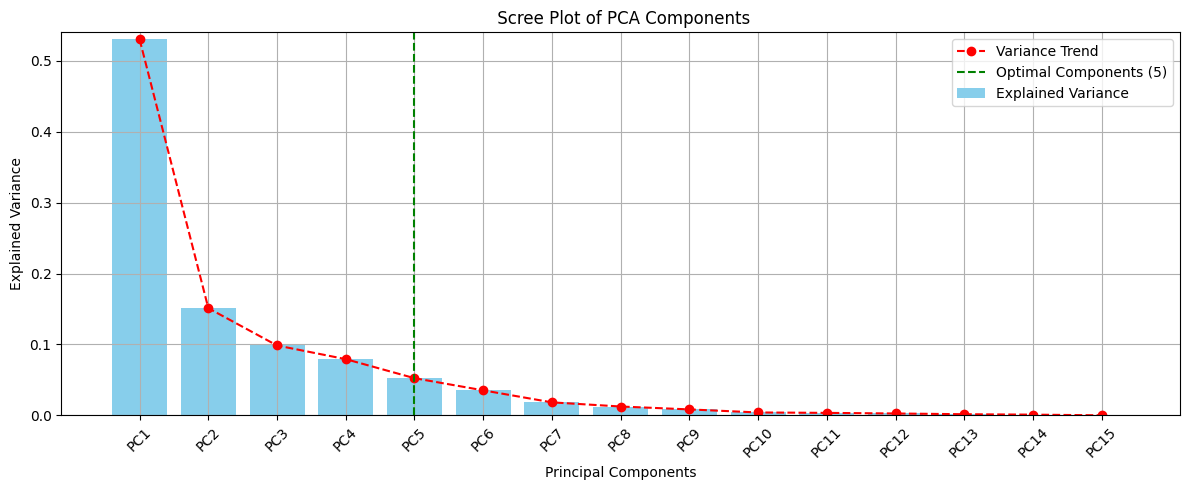

In [98]:
cumulative_variance = np.cumsum(pca_out.explained_variance_ratio_)
optimal_components = np.argmax(cumulative_variance >= 0.90) + 1

component_numbers = list(range(1, len(pc_list) + 1))

plt.figure(figsize=(12, 5))

plt.bar(component_numbers, pca_out.explained_variance_ratio_, color='skyblue', label='Explained Variance')

plt.plot(component_numbers, pca_out.explained_variance_ratio_, marker='o', linestyle='--', color='red', label='Variance Trend')

plt.axvline(x=optimal_components, color='green', linestyle='--', label=f"Optimal Components ({optimal_components})")

plt.xticks(component_numbers, pc_list, rotation=45)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title(' Scree Plot of PCA Components')
plt.ylim(0, max(pca_out.explained_variance_ratio_) + 0.01)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

## Navie Bayes

In [99]:
pca_model.fit(X_train_fsfs_NB)

cum_var = np.cumsum(pca_model.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1
pca_final = PCA(n_components=n_components_95)
X_train_pca_nb = pca_final.fit_transform(X_train_fsfs_NB)
X_test_pca_nb = pca_final.transform(X_test_fsfs_NB)
gnb.fit(X_train_pca_nb, Y_train_OS)
y_pred_pca = gnb.predict(X_test_pca_nb)

print("\nClassification Report:\n", classification_report(Y_test, y_pred_pca))
conf_matrix = confusion_matrix(Y_test, y_pred_pca)
conf_matrix_df = pd.DataFrame(conf_matrix, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
display(conf_matrix_df)


Classification Report:
               precision    recall  f1-score   support

         0.0       0.94      0.97      0.95        60
         1.0       0.89      0.80      0.84        20

    accuracy                           0.93        80
   macro avg       0.91      0.88      0.90        80
weighted avg       0.92      0.93      0.92        80



,Predicted 0,Predicted 1
Actual 0,58,2
Actual 1,4,16


In [134]:
gnb.fit(X_train_pca_nb, Y_train_OS)
scores = cross_val_score(gnb, X_train_pca_nb, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.875000
1,0.947917
2,0.958333
3,0.906250
4,0.937500


The Avarage of CV Scores:  0.925


In [100]:
pca_out = PCA()
pca_scores = pca_out.fit_transform(X_train_fsfs_NB)
pc_list = [f"PC{i}" for i in range(1, pca_scores.shape[1] + 1)]
df_pca = pd.DataFrame(pca_scores, columns=pc_list)
df_pca['diagnosis'] = Y_train_OS
df_explained_variance_cumsum = pd.DataFrame(
    [np.cumsum(pca_out.explained_variance_ratio_)],
    columns=pc_list
)

In [101]:
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,diagnosis
0,-0.396716,-0.108360,-0.002005,0.033522,-0.136797,0.043447,0.041485,0.105656,-0.051703,0.002598,-0.080053,-0.003232,0.003128,0.013079,0.004328,0.0
1,-0.464894,-0.058788,0.125695,0.198785,-0.030602,-0.126411,0.150848,0.016476,0.031839,0.022719,-0.004413,-0.013566,0.026625,-0.005262,0.008032,0.0
2,-0.721311,-0.054470,0.085939,-0.192601,0.007562,-0.002963,0.057752,0.157526,-0.025461,0.017593,-0.010621,0.011278,-0.002773,0.008329,-0.008777,0.0
3,-0.306951,-0.394107,0.329453,-0.490610,-0.329252,0.322989,0.022361,0.186666,-0.008293,-0.162068,0.058844,-0.004888,-0.069662,0.017429,-0.009463,0.0
4,-0.370054,-0.800628,-0.453698,0.294017,-0.016958,-0.125046,0.060879,0.061898,0.030294,-0.025132,0.026510,-0.014217,-0.019499,0.047080,-0.034807,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.430861,-0.137069,-0.293620,-0.048641,-0.267987,0.108804,0.030893,0.000826,-0.054743,0.057800,0.012388,0.083920,-0.000527,-0.014969,0.003184,1.0
476,0.556699,-0.322588,-0.227927,0.336941,-0.161812,0.054103,0.043252,-0.074277,0.023039,-0.037040,0.144407,-0.005982,0.013809,-0.013671,-0.002118,1.0
477,0.413564,-0.206899,-0.524856,-0.018991,-0.079461,0.180302,0.030773,-0.012580,-0.075905,-0.045389,0.023037,0.059183,0.012398,-0.011679,0.002042,1.0
478,0.061067,-0.109420,-0.264176,-0.008499,0.141256,0.038081,-0.181278,0.002748,-0.012967,0.053533,-0.054179,-0.012163,-0.018275,-0.001436,0.006396,1.0


In [102]:
df_explained_variance_cumsum

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,0.353009,0.60901,0.751195,0.844526,0.913066,0.937674,0.960496,0.972322,0.982289,0.989227,0.995304,0.99775,0.999058,0.999698,1.0


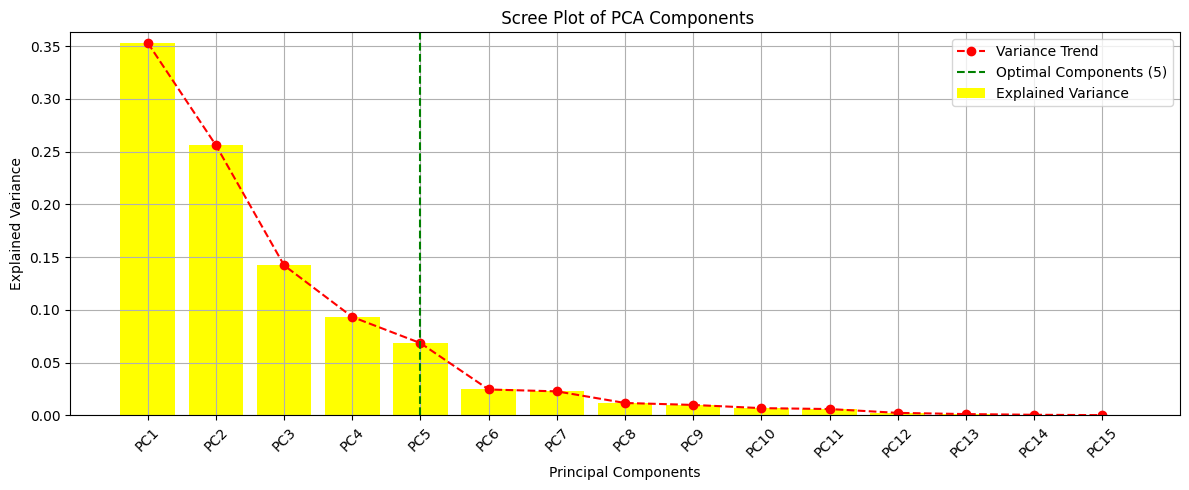

In [103]:
cumulative_variance = np.cumsum(pca_out.explained_variance_ratio_)
optimal_components = np.argmax(cumulative_variance >= 0.90) + 1

component_numbers = list(range(1, len(pc_list) + 1))

plt.figure(figsize=(12, 5))

plt.bar(component_numbers, pca_out.explained_variance_ratio_, color='yellow', label='Explained Variance')

plt.plot(component_numbers, pca_out.explained_variance_ratio_, marker='o', linestyle='--', color='red', label='Variance Trend')

plt.axvline(x=optimal_components, color='green', linestyle='--', label=f"Optimal Components ({optimal_components})")

plt.xticks(component_numbers, pc_list, rotation=45)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title(' Scree Plot of PCA Components')
plt.ylim(0, max(pca_out.explained_variance_ratio_) + 0.01)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

## Nearest Neighbor

In [104]:
pca_model.fit(X_train_fsfs_NN)

cum_var = np.cumsum(pca_model.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1
pca_final = PCA(n_components=n_components_95)
X_train_pca_nn = pca_final.fit_transform(X_train_fsfs_NN)
X_test_pca_nn = pca_final.transform(X_test_fsfs_NN)
nn.fit(X_train_pca_nn, Y_train_OS)
y_pred_pca = nn.predict(X_test_pca_nn)

print("\nClassification Report:\n", classification_report(Y_test, y_pred_pca))
conf_matrix = confusion_matrix(Y_test, y_pred_pca)
conf_matrix_df = pd.DataFrame(conf_matrix, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
display(conf_matrix_df)


Classification Report:
               precision    recall  f1-score   support

         0.0       0.95      0.95      0.95        60
         1.0       0.85      0.85      0.85        20

    accuracy                           0.93        80
   macro avg       0.90      0.90      0.90        80
weighted avg       0.93      0.93      0.93        80



,Predicted 0,Predicted 1
Actual 0,57,3
Actual 1,3,17


In [135]:
nn.fit(X_train_pca_nn, Y_train_OS)
scores = cross_val_score(nn, X_train_pca_nn, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.979167
1,0.968750
2,1.000000
3,0.979167
4,0.958333


The Avarage of CV Scores:  0.9770833333333332


In [105]:
pca_out = PCA()
pca_scores = pca_out.fit_transform(X_train_fsfs_NN)
pc_list = [f"PC{i}" for i in range(1, pca_scores.shape[1] + 1)]
df_pca = pd.DataFrame(pca_scores, columns=pc_list)
df_pca['diagnosis'] = Y_train_OS
df_explained_variance_cumsum = pd.DataFrame(
    [np.cumsum(pca_out.explained_variance_ratio_)],
    columns=pc_list
)

In [106]:
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,diagnosis
0,-0.538421,-0.005779,0.007620,-0.121526,-0.028907,-0.032896,0.095146,0.025254,0.041822,-0.045801,-0.016829,-0.022929,-0.006115,-0.001010,0.000988,0.0
1,-0.527075,-0.039706,0.114876,-0.218263,-0.003319,-0.020540,0.065808,-0.060637,0.036011,0.016394,0.021707,0.020065,-0.004337,0.006009,0.000990,0.0
2,-0.845559,-0.284532,-0.028986,0.058330,0.010411,0.006496,0.087979,0.063846,0.159877,0.010085,-0.035458,-0.040027,0.008986,-0.007075,0.001580,0.0
3,-0.725742,0.023832,0.281097,0.190072,0.110634,0.330542,0.217345,0.061910,0.065088,0.027119,-0.062510,-0.058914,-0.005920,-0.003336,-0.001765,0.0
4,-0.826930,0.766969,-0.343238,-0.140041,0.027959,-0.140898,0.023462,-0.074430,0.068335,0.050737,0.001397,-0.025754,-0.037510,-0.038311,-0.002942,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.472954,0.284533,-0.190987,0.122674,0.267667,-0.083281,0.106999,0.190620,0.043898,-0.080416,0.015338,-0.003066,0.020657,0.008420,0.004215,1.0
476,0.465196,0.724726,-0.025543,-0.123058,0.104821,0.011821,0.063087,0.016874,-0.066504,0.070858,-0.039573,0.039521,0.007235,0.005757,0.000530,1.0
477,0.468781,0.427756,-0.427515,0.171053,0.111899,-0.048325,0.121034,0.205076,0.008001,-0.048041,-0.027400,-0.009539,0.009834,0.009735,-0.000011,1.0
478,0.020841,0.185811,-0.248340,0.074269,-0.141617,-0.020376,-0.131486,0.001279,-0.013942,-0.021021,-0.018645,-0.016176,0.014670,0.005918,0.002641,1.0


In [107]:
df_explained_variance_cumsum


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,0.48093,0.698037,0.829394,0.887692,0.920981,0.946867,0.966037,0.979598,0.989258,0.993706,0.996722,0.99902,0.999675,0.999986,1.0


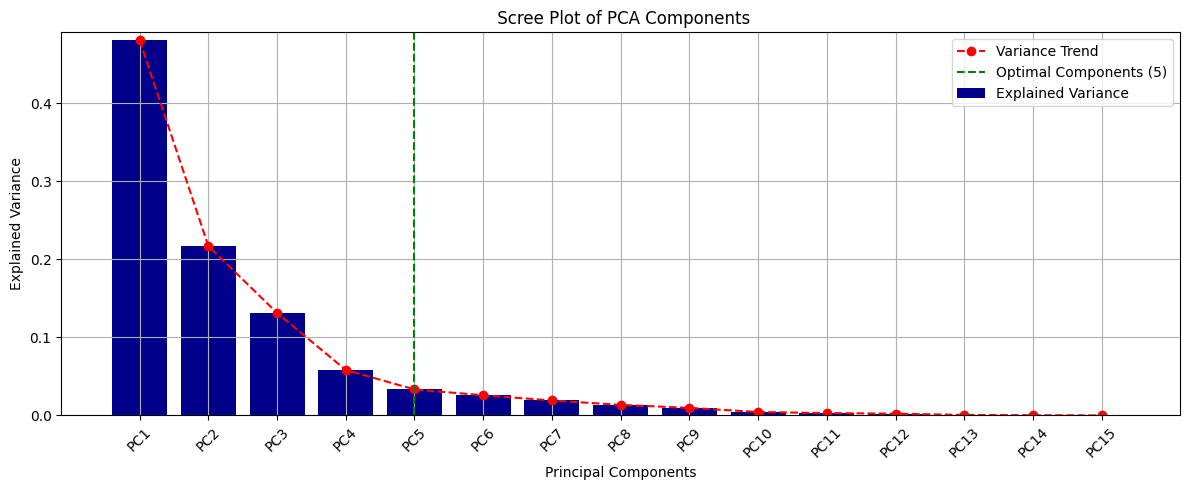

In [108]:
cumulative_variance = np.cumsum(pca_out.explained_variance_ratio_)
optimal_components = np.argmax(cumulative_variance >= 0.90) + 1

component_numbers = list(range(1, len(pc_list) + 1))

plt.figure(figsize=(12, 5))

plt.bar(component_numbers, pca_out.explained_variance_ratio_, color='darkblue', label='Explained Variance')

plt.plot(component_numbers, pca_out.explained_variance_ratio_, marker='o', linestyle='--', color='red', label='Variance Trend')

plt.axvline(x=optimal_components, color='green', linestyle='--', label=f"Optimal Components ({optimal_components})")

plt.xticks(component_numbers, pc_list, rotation=45)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title(' Scree Plot of PCA Components')
plt.ylim(0, max(pca_out.explained_variance_ratio_) + 0.01)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

## KNN

In [69]:
pca_model.fit(X_train_fsfs_KNN)

cum_var = np.cumsum(pca_model.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1
pca_final = PCA(n_components=n_components_95)
X_train_pca_knn = pca_final.fit_transform(X_train_fsfs_KNN)
X_test_pca_knn = pca_final.transform(X_test_fsfs_KNN)
KNN.fit(X_train_pca_knn, Y_train_OS)
y_pred_pca = KNN.predict(X_test_pca_knn)

print("\nClassification Report:\n", classification_report(Y_test, y_pred_pca))
conf_matrix = confusion_matrix(Y_test, y_pred_pca)
conf_matrix_df = pd.DataFrame(conf_matrix, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
display(conf_matrix_df)


Classification Report:
               precision    recall  f1-score   support

         0.0       0.97      1.00      0.98        60
         1.0       1.00      0.90      0.95        20

    accuracy                           0.97        80
   macro avg       0.98      0.95      0.97        80
weighted avg       0.98      0.97      0.97        80



,Predicted 0,Predicted 1
Actual 0,60,0
Actual 1,2,18


In [70]:
KNN.fit(X_train_pca_knn, Y_train_OS)
scores = cross_val_score(KNN, X_train_pca_knn, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.968750
1,1.000000
2,1.000000
3,0.989583
4,0.958333


The Avarage of CV Scores:  0.9833333333333334


In [71]:
pca_out = PCA()
pca_scores = pca_out.fit_transform(X_train_fsfs_KNN)
pc_list = [f"PC{i}" for i in range(1, pca_scores.shape[1] + 1)]
df_pca = pd.DataFrame(pca_scores, columns=pc_list)
df_pca['diagnosis'] = Y_train_OS
df_explained_variance_cumsum = pd.DataFrame(
    [np.cumsum(pca_out.explained_variance_ratio_)],
    columns=pc_list
)

In [72]:
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,diagnosis
0,-0.565209,0.000989,-0.000136,-0.121586,0.061449,0.107748,0.078915,0.028062,-0.053029,-0.027980,0.018817,-0.002719,-0.001305,0.003370,-0.000603,0.0
1,-0.573646,-0.088558,0.144361,-0.195090,-0.066853,0.049164,-0.049648,-0.084755,-0.000951,0.026856,0.004755,0.001005,0.006944,-0.001375,-0.001702,0.0
2,-0.879145,-0.303561,0.037854,0.079436,-0.038185,0.038081,0.091746,-0.180478,-0.016711,-0.028820,-0.037736,-0.000778,-0.007770,0.000782,-0.000603,0.0
3,-0.756786,0.096868,0.251407,0.162658,0.460365,0.025787,0.102191,-0.132286,-0.040313,-0.081811,-0.038336,-0.017464,-0.009362,0.008720,0.000122,0.0
4,-0.976380,0.363735,-0.428841,-0.092650,-0.227257,0.019729,-0.040179,-0.063802,-0.061293,0.019624,-0.035684,-0.069964,-0.037995,0.004623,0.000268,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.448256,0.053579,-0.178666,0.166322,-0.035064,-0.076950,0.266072,-0.010523,0.003133,0.002410,0.031289,0.036327,-0.004043,0.005403,-0.005650,1.0
476,0.386240,0.528534,-0.128537,-0.125675,0.023990,-0.052081,0.027677,0.010790,-0.022459,-0.066903,0.025932,0.006947,-0.002528,-0.003082,-0.002109,1.0
477,0.439398,0.170424,-0.460050,0.179917,-0.033455,-0.008021,0.245152,-0.035281,0.055666,-0.034713,0.004745,0.018076,0.004543,0.001225,-0.000565,1.0
478,0.004688,0.197619,-0.315587,0.051880,-0.054026,-0.016148,-0.032144,0.065723,0.013989,-0.018864,-0.005852,0.016109,0.006243,0.000662,-0.001097,1.0


In [73]:
df_explained_variance_cumsum


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,0.549484,0.712573,0.843213,0.899751,0.935841,0.960015,0.973979,0.986325,0.992248,0.995968,0.998488,0.999486,0.999928,0.999986,1.0


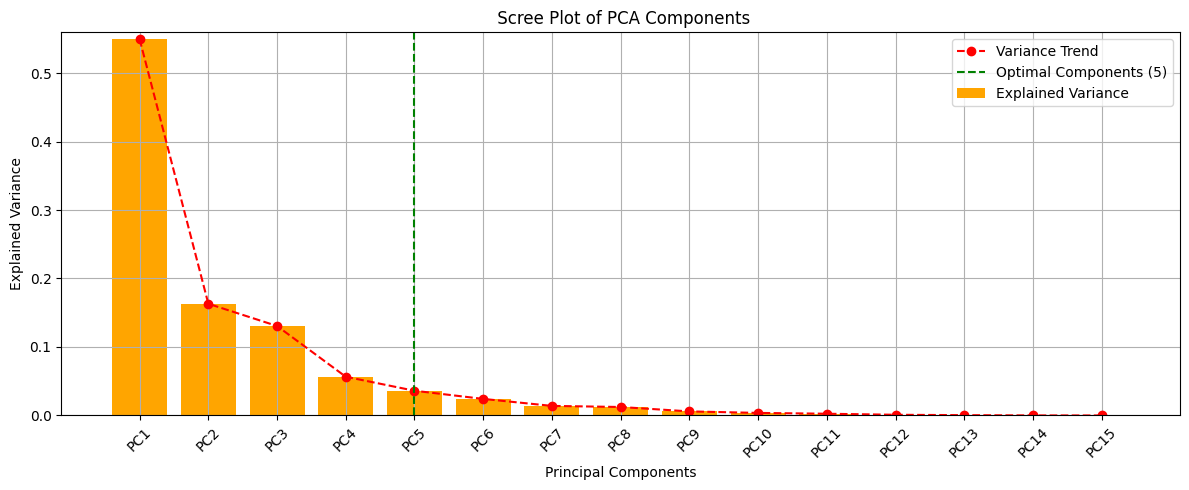

In [74]:
cumulative_variance = np.cumsum(pca_out.explained_variance_ratio_)
optimal_components = np.argmax(cumulative_variance >= 0.90) + 1

component_numbers = list(range(1, len(pc_list) + 1))

plt.figure(figsize=(12, 5))

plt.bar(component_numbers, pca_out.explained_variance_ratio_, color='orange', label='Explained Variance')

plt.plot(component_numbers, pca_out.explained_variance_ratio_, marker='o', linestyle='--', color='red', label='Variance Trend')

plt.axvline(x=optimal_components, color='green', linestyle='--', label=f"Optimal Components ({optimal_components})")

plt.xticks(component_numbers, pc_list, rotation=45)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title(' Scree Plot of PCA Components')
plt.ylim(0, max(pca_out.explained_variance_ratio_) + 0.01)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

## NC

In [114]:
pca_model.fit(X_train_fsfs_NC)

cum_var = np.cumsum(pca_model.explained_variance_ratio_)
n_components_95 = np.argmax(cum_var >= 0.95) + 1
pca_final = PCA(n_components=n_components_95)
X_train_pca_nc = pca_final.fit_transform(X_train_fsfs_NC)
X_test_pca_nc = pca_final.transform(X_test_fsfs_NC)
NC.fit(X_train_pca_nc, Y_train_OS)
y_pred_pca = NC.predict(X_test_pca_nc)

print("\nClassification Report:\n", classification_report(Y_test, y_pred_pca))
conf_matrix = confusion_matrix(Y_test, y_pred_pca)
conf_matrix_df = pd.DataFrame(conf_matrix, columns=["Predicted 0", "Predicted 1"], index=["Actual 0", "Actual 1"])
display(conf_matrix_df)


Classification Report:
               precision    recall  f1-score   support

         0.0       0.97      1.00      0.98        60
         1.0       1.00      0.90      0.95        20

    accuracy                           0.97        80
   macro avg       0.98      0.95      0.97        80
weighted avg       0.98      0.97      0.97        80



,Predicted 0,Predicted 1
Actual 0,60,0
Actual 1,2,18


In [137]:
NC.fit(X_train_pca_nc, Y_train_OS)
scores = cross_val_score(NC, X_train_pca_nc, Y_train_OS, cv=CV)


score_df = pd.DataFrame(scores,columns=['Accuracy'])
display(score_df)
print('The Avarage of CV Scores: ',score_df.Accuracy.mean())

,Accuracy
0,0.947917
1,0.989583
2,0.989583
3,0.958333
4,0.968750


The Avarage of CV Scores:  0.9708333333333334


In [115]:
pca_out = PCA()
pca_scores = pca_out.fit_transform(X_train_fsfs_NC)
pc_list = [f"PC{i}" for i in range(1, pca_scores.shape[1] + 1)]
df_pca = pd.DataFrame(pca_scores, columns=pc_list)
df_pca['diagnosis'] = Y_train_OS
df_explained_variance_cumsum = pd.DataFrame(
    [np.cumsum(pca_out.explained_variance_ratio_)],
    columns=pc_list
)

In [116]:
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,diagnosis
0,-0.416134,-0.132922,0.030063,0.070315,-0.069703,-0.025243,0.101597,0.036674,0.062070,-0.155505,0.006240,0.004026,-0.025956,-0.009362,-0.000348,0.0
1,-0.471402,-0.011957,0.129527,0.101906,0.124673,0.112637,0.043048,-0.082123,-0.078479,-0.062168,0.004944,-0.002603,0.041246,-0.008346,-0.011991,0.0
2,-0.695184,-0.250875,0.139417,-0.122281,-0.122488,0.046446,-0.003005,0.120845,0.048032,-0.082069,0.011855,-0.024455,0.003227,0.010666,0.019736,0.0
3,-0.600104,0.280803,0.264686,-0.228816,-0.042503,-0.547274,0.126050,0.292999,0.124748,-0.099413,-0.078895,0.034508,-0.031322,0.034259,0.035427,0.0
4,-0.765260,0.234315,-0.583119,0.099299,-0.072680,0.202536,0.080372,-0.066561,0.044229,-0.059868,-0.012796,0.012771,-0.018334,-0.059097,0.041634,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.226251,-0.017412,-0.260338,0.049142,-0.244889,-0.173327,0.065547,0.012384,-0.049157,0.118185,-0.062331,0.012603,-0.006098,0.020360,-0.009713,1.0
476,0.360949,0.412804,-0.381924,0.241252,0.057265,-0.049076,0.172717,-0.044651,0.066522,0.087897,0.006913,-0.082586,0.022829,-0.007277,-0.005500,1.0
477,0.234997,0.024380,-0.474672,-0.119355,-0.128773,-0.126742,0.118579,0.036948,0.023243,0.087534,-0.056127,0.008467,0.007670,0.024729,-0.004437,1.0
478,-0.023120,-0.003397,-0.251183,-0.065873,0.097181,0.051575,-0.060525,0.012365,0.101133,0.030034,0.040447,0.071242,-0.008341,0.008224,-0.010306,1.0


In [117]:
df_explained_variance_cumsum

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,0.40935,0.603959,0.734863,0.821952,0.878261,0.927059,0.949848,0.967822,0.978299,0.987116,0.993121,0.997425,0.998809,0.999638,1.0


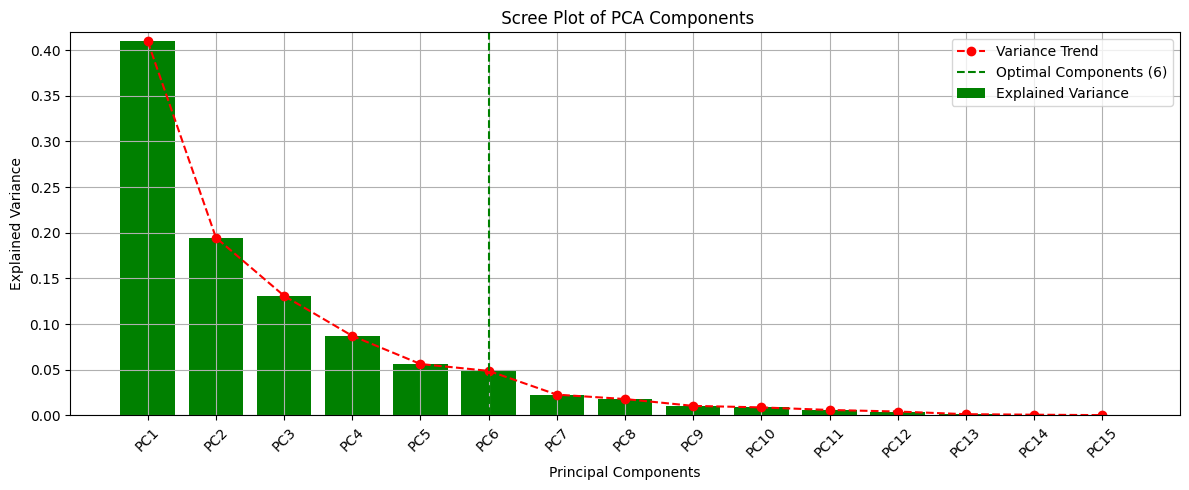

In [118]:
cumulative_variance = np.cumsum(pca_out.explained_variance_ratio_)
optimal_components = np.argmax(cumulative_variance >= 0.90) + 1

component_numbers = list(range(1, len(pc_list) + 1))

plt.figure(figsize=(12, 5))

plt.bar(component_numbers, pca_out.explained_variance_ratio_, color='green', label='Explained Variance')

plt.plot(component_numbers, pca_out.explained_variance_ratio_, marker='o', linestyle='--', color='red', label='Variance Trend')

plt.axvline(x=optimal_components, color='green', linestyle='--', label=f"Optimal Components ({optimal_components})")

plt.xticks(component_numbers, pc_list, rotation=45)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title(' Scree Plot of PCA Components')
plt.ylim(0, max(pca_out.explained_variance_ratio_) + 0.01)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

# ROC Curve

## MLP

No Skill: ROC AUC=0.500
MLP: ROC AUC = 98.000%


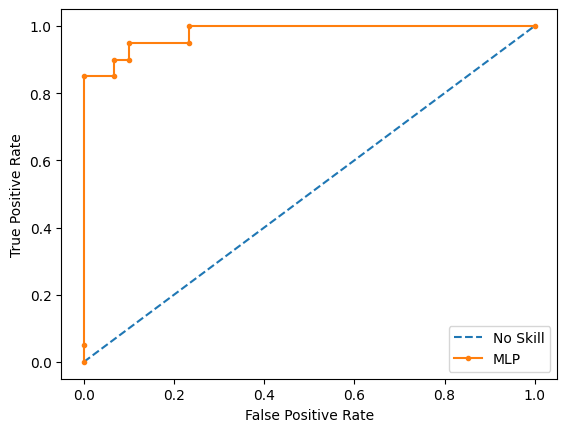

In [119]:
ns_probs = [0 for _ in range(len(Y_test))]

MLP_lr_probs = MLP.predict_proba(X_test_pca_mlp)
MLP_lr_probs = MLP_lr_probs[:,1]
ns_auc = roc_auc_score(Y_test,ns_probs)
MLP_lr_auc = roc_auc_score(Y_test,MLP_lr_probs)
print('No Skill: ROC AUC=%.3f'%(ns_auc))
print('MLP: ROC AUC = %.3f%%' % (MLP_lr_auc * 100))

ns_fpr,ns_tpr,_=roc_curve(Y_test,ns_probs)
MLP_lr_fpr,MLP_lr_tpr,_ = roc_curve(Y_test,MLP_lr_probs)

plt.plot(ns_fpr,ns_tpr,linestyle = '--',label = 'No Skill')
plt.plot(MLP_lr_fpr,MLP_lr_tpr,marker = '.',label = 'MLP')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()

## NB

No Skill: ROC AUC=0.500
NB: ROC AUC = 92.000%


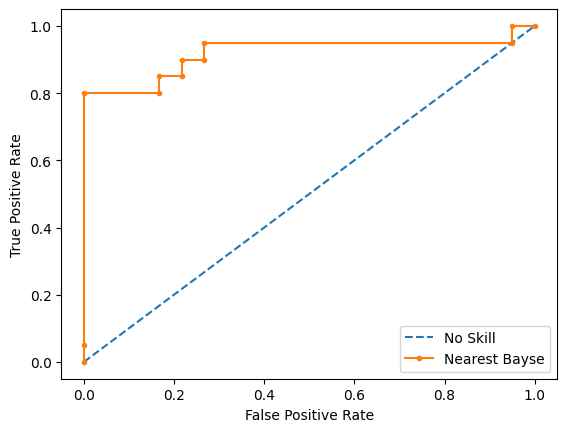

In [120]:
ns_probs = [0 for _ in range(len(Y_test))]

NB_lr_probs = gnb.predict_proba(X_test_pca_nb)
NB_lr_probs= NB_lr_probs[:,1]
ns_auc = roc_auc_score(Y_test,ns_probs)
NB_lr_auc = roc_auc_score(Y_test,NB_lr_probs)
print('No Skill: ROC AUC=%.3f'%(ns_auc))
print('NB: ROC AUC = %.3f%%' % (NB_lr_auc * 100))

ns_fpr,ns_tpr,_=roc_curve(Y_test,ns_probs)
NB_lr_fpr,NB_lr_tpr,_ = roc_curve(Y_test,NB_lr_probs)

plt.plot(ns_fpr,ns_tpr,linestyle = '--',label = 'No Skill')
plt.plot(NB_lr_fpr,NB_lr_tpr,marker = '.',label = 'Nearest Bayse')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()

# NN

No Skill: ROC AUC=0.500
NN: ROC AUC = 90.000%


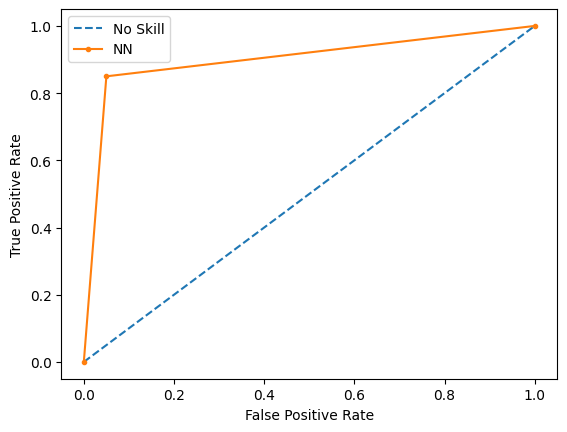

In [121]:
ns_probs = [0 for _ in range(len(Y_test))]

NN_lr_probs = nn.predict_proba(X_test_pca_nn)
NN_lr_probs = NN_lr_probs[:,1]
ns_auc = roc_auc_score(Y_test,ns_probs)
NN_lr_auc = roc_auc_score(Y_test,NN_lr_probs)
print('No Skill: ROC AUC=%.3f'%(ns_auc))
print('NN: ROC AUC = %.3f%%' % (NN_lr_auc * 100))

ns_fpr,ns_tpr,_=roc_curve(Y_test,ns_probs)
NN_lr_fpr,MLP_lr_tpr,_ = roc_curve(Y_test,NN_lr_probs)

plt.plot(ns_fpr,ns_tpr,linestyle = '--',label = 'No Skill')
plt.plot(NN_lr_fpr,MLP_lr_tpr,marker = '.',label = 'NN')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()

## KNN

No Skill: ROC AUC=0.500
KNN: ROC AUC = 94.833%


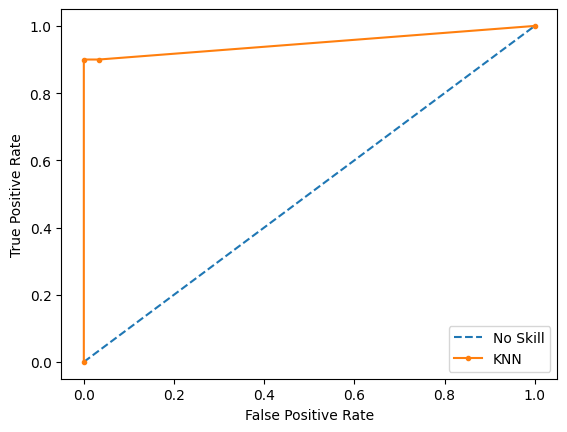

In [122]:
ns_probs = [0 for _ in range(len(Y_test))]

KNN_lr_probs = KNN.predict_proba(X_test_pca_knn)
KNN_lr_probs = KNN_lr_probs[:,1]
ns_auc = roc_auc_score(Y_test,ns_probs)
KNN_lr_auc = roc_auc_score(Y_test,KNN_lr_probs)
print('No Skill: ROC AUC=%.3f'%(ns_auc))
print('KNN: ROC AUC = %.3f%%' % (KNN_lr_auc * 100))

ns_fpr,ns_tpr,_=roc_curve(Y_test,ns_probs)
KNN_lr_fpr,KNN_lr_tpr,_ = roc_curve(Y_test,KNN_lr_probs)

plt.plot(ns_fpr,ns_tpr,linestyle = '--',label = 'No Skill')
plt.plot(KNN_lr_fpr,KNN_lr_tpr,marker = '.',label = 'KNN')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()

## NC

No Skill: ROC AUC=0.500
NC: ROC AUC = 97.417%


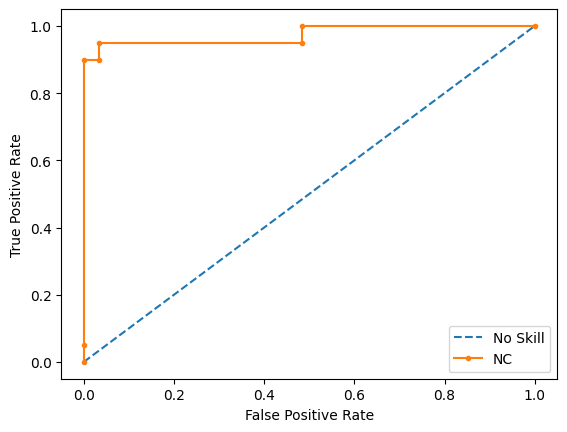

In [123]:
ns_probs = [0 for _ in range(len(Y_test))]

NC_lr_probs = NC.predict_proba(X_test_pca_nc)
NC_lr_probs = NC_lr_probs[:,1]
ns_auc = roc_auc_score(Y_test,ns_probs)
NC_lr_auc = roc_auc_score(Y_test,NC_lr_probs)
print('No Skill: ROC AUC=%.3f'%(ns_auc))
print('NC: ROC AUC = %.3f%%' % (NC_lr_auc * 100))


ns_fpr,ns_tpr,_=roc_curve(Y_test,ns_probs)
NC_lr_fpr,NC_lr_tpr,_ = roc_curve(Y_test,NC_lr_probs)

plt.plot(ns_fpr,ns_tpr,linestyle = '--',label = 'No Skill')
plt.plot(NC_lr_fpr,NC_lr_tpr,marker = '.',label = 'NC')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()